<a href="https://colab.research.google.com/github/murilovieirasp/API_google_maps/blob/main/C%C3%B3pia_de_atividade_bigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
data = pd.read_csv('/content/drive/MyDrive/Classroom/Big Data e Data Science 2026 02 - IA 2/datase_óbitos.csv', encoding='latin-1', sep=';')
data

,Localidade,Variável,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
0,Acreúna,Óbitos por suicídios (número),0,1,1,1,2,3,2,2,2,3,2
1,Anápolis,Óbitos por suicídios (número),16,27,23,23,30,23,37,40,39,34,45
2,Aparecida de Goiânia,Óbitos por suicídios (número),35,36,28,36,43,37,38,45,48,56,52
3,Catalão,Óbitos por suicídios (número),4,9,6,7,8,10,8,10,11,12,12
4,Goiânia,Óbitos por suicídios (número),88,93,74,104,142,120,123,148,142,143,168
5,Goiás,Óbitos por suicídios (número),1,5,0,5,3,2,2,6,2,4,8
6,Goiatuba,Óbitos por suicídios (número),2,3,1,5,2,4,4,7,2,5,6
7,Hidrolândia,Óbitos por suicídios (número),0,2,4,-,3,4,1,2,1,2,2
8,Inhumas,Óbitos por suicídios (número),6,6,0,2,4,2,3,5,4,8,3
9,Iporá,Óbitos por suicídios (número),2,1,4,4,1,2,6,5,2,3,3


In [ ]:
# Preparação dos dados
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Criar uma cópia dos dados para tratamento
data_clean = data.copy()

# Substituir o caractere '-' por '0' e converter as colunas de anos para numérico
anos = [str(ano) for ano in range(2015, 2026)]
for col in anos:
    data_clean[col] = data_clean[col].astype(str).str.replace('-', '0').str.strip()
    data_clean[col] = pd.to_numeric(data_clean[col], errors='coerce').fillna(0).astype(int)

# Definição das variáveis preditoras (X - anos de 2015 a 2024) e do alvo (y - ano de 2025)
features = [str(ano) for ano in range(2015, 2025)]
X = data_clean[features]
y = data_clean['2025']

# Divisão em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Criação e Treino do Modelo Random Forest Regressor
modelo_RFRegressor = RandomForestRegressor(random_state=42)
modelo_RFRegressor.fit(X_train, y_train)

# 2. Fazendo previsões na base de teste
predicaoRFRegressor = modelo_RFRegressor.predict(X_test)

# 3. Exibindo os resultados comparativos
resultados_rf = pd.DataFrame({
    'Município': data_clean.loc[X_test.index, 'Localidade'],
    'Real (2025)': y_test.values,
    'Previsto pelo RF': predicaoRFRegressor.round().astype(int)
})

print("RESULTADOS DA PREVISÃO DO RANDOM FOREST")
display(resultados_rf)

RESULTADOS DA PREVISÃO DO RANDOM FOREST


,Município,Real (2025),Previsto pelo RF
0,Acreúna,2,3
1,Anápolis,45,27
5,Goiás,8,5
14,Rio Verde,23,14


In [ ]:
#KNN
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Criar instância de KNN (usando 3 vizinhos)
knnR = KNeighborsRegressor(n_neighbors=3)

# 2. Treinar o modelo com as variáveis corretas existentes no notebook
knnR.fit(X_train, y_train)

# 3. Predição na base de teste apropriada
previsoes_knn = knnR.predict(X_test)

# 4. Criando DataFrame comparativo para visualização
resultados_knn = pd.DataFrame({
    'Município': data.loc[X_test.index, 'Localidade'],
    'Real (2025)': y_test.values,
    'Previsto pelo KNN': previsoes_knn.round().astype(int)
})

print("RESULTADOS DA PREVISÃO DO KNN")
display(resultados_knn)

# 5. Cálculo das métricas
mse_knn = mean_squared_error(y_test, previsoes_knn)
r2_knn = r2_score(y_test, previsoes_knn)
print(f"\nErro Quadrático Médio (MSE): {mse_knn:.2f}")
print(f"Coeficiente de Determinação (R²): {r2_knn:.2f}")

RESULTADOS DA PREVISÃO DO KNN


,Município,Real (2025),Previsto pelo KNN
0,Acreúna,2,3
1,Anápolis,45,27
5,Goiás,8,4
14,Rio Verde,23,11



Erro Quadrático Médio (MSE): 124.14
Coeficiente de Determinação (R²): 0.55


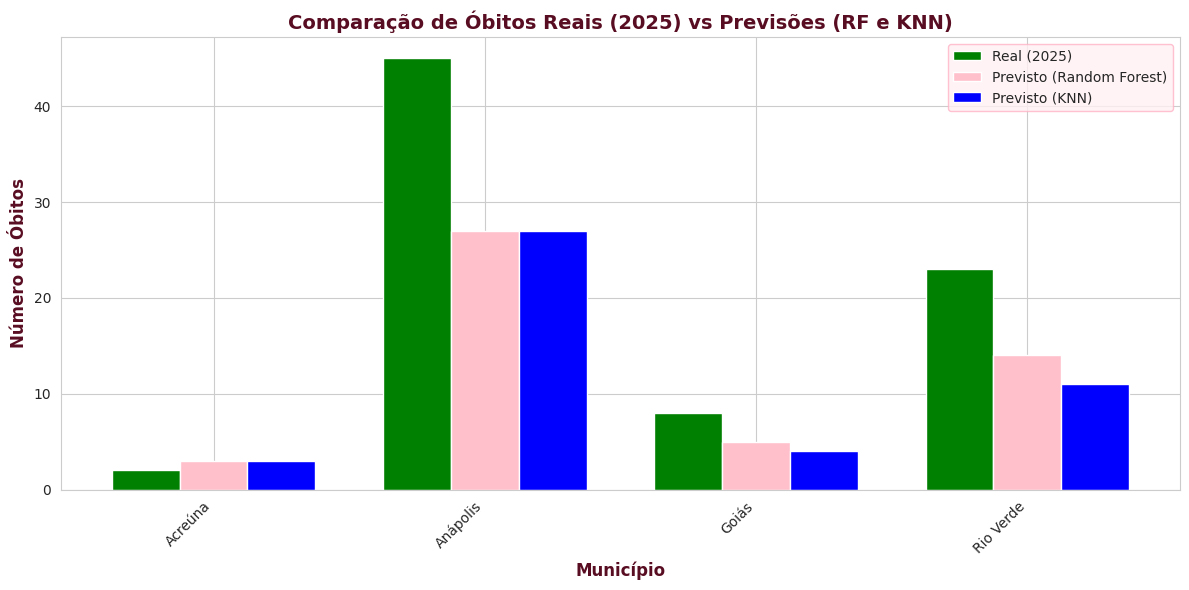

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agora as variáveis estarão definidas e o gráfico será exibido corretamente
if 'resultados_rf' in locals() and 'resultados_knn' in locals():
    df_plot = resultados_rf.merge(resultados_knn[['Município', 'Previsto pelo KNN']], on='Município')

    # Configurando o estilo e a cor rosa
    plt.figure(figsize=(12, 6))
    sns.set_style("whitegrid")

    # Definindo as posições das barras
    x = np.arange(len(df_plot['Município']))
    width = 0.25

    # Plotando as barras com paleta de cores rosa/rosa-escuro/magenta
    plt.bar(x - width, df_plot['Real (2025)'], width, label='Real (2025)', color='green')
    plt.bar(x, df_plot['Previsto pelo RF'], width, label='Previsto (Random Forest)', color='pink')
    plt.bar(x + width, df_plot['Previsto pelo KNN'], width, label='Previsto (KNN)', color='blue')

    # Customizações adicionais
    plt.xlabel('Município', fontsize=12, fontweight='bold', color='#590d22')
    plt.ylabel('Número de Óbitos', fontsize=12, fontweight='bold', color='#590d22')
    plt.title('Comparação de Óbitos Reais (2025) vs Previsões (RF e KNN)', fontsize=14, fontweight='bold', color='#590d22')
    plt.xticks(x, df_plot['Município'], rotation=45, ha='right')
    plt.legend(facecolor='#fff0f3', edgecolor='#ffb3c6')

    plt.tight_layout()
    plt.show()
else:
    print("Por favor, execute novamente as células acima para definir os resultados.")